# Don't Get Kicked — EDA: why this preprocessing

## Preprocessing scheme

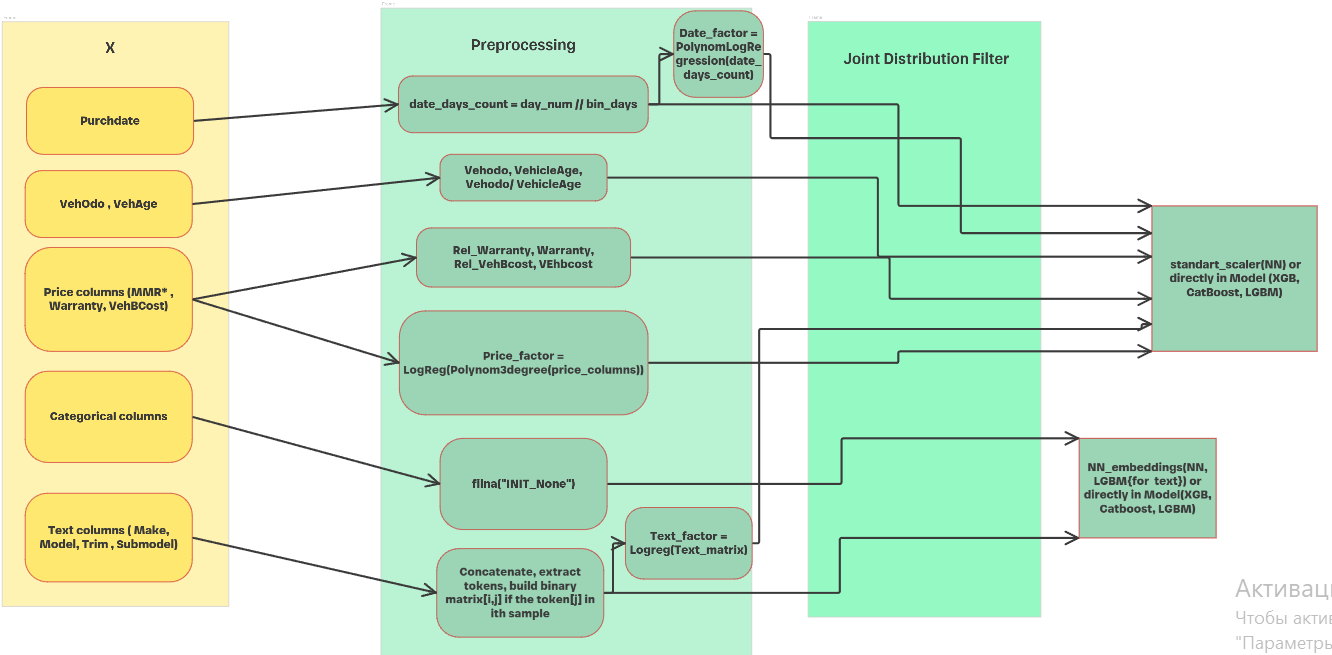

This notebook motivates the project's `Preprocessing` and `JointDistributionFilter` (JDF) step by step:

1. Target and missing values.
2. **Price garbage** – why values < 100 are replaced and flagged.
3. **Relative features** vs raw columns.
4. **`Date_factor`** – a polynomial of the purchase date vs the empirical share of ones in 14-day bins.
5. **`price_factor` / `text_factor`** – sorted values vs the base rate, in-sample vs out-of-fold AUC.
6. **XGBoost on fold 0** with `Preprocessing` + JDF and a `feature_importance` table.
7. **How the JDF works**, with an interactive generator of distribution plots (train vs test).



## Code: preprocessing classes (JDF with its plotting method)

In [ ]:
import re
from collections import Counter
from typing import Optional

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import matplotlib.pyplot as plt
import xgboost as xgb

SEED, K = 42, 5
TRAIN_PATH = "dont_get_kicked/datasets/training.csv"
TEST_PATH = "dont_get_kicked/datasets/test.csv"
DATE_DAYS = 14        # width of a date bin (days)
N_ITER = 350      

CFG = {
      "rank": 0,
      "outer_trial": 1,
      "val_auc": 0.7961059357455899,
      "best_estimators": 313,
      "preprocessing": {
        "date_days": 23,
        "text_min_count_train": 161
      },
      "inner_trial": 44,
      "jdf": {
        "dp": 0.0228507706202372,
        "th_num_train": 0.00029849077787525867,
        "th_num_test": 0.028341234995081947,
        "th_cat_train": 0.005204874749618135,
        "th_cat_test": 0.003683159071520922
      },
      "fid": {
        "n_worst": 162
      },
      "xgb": {
        "objective": "binary:logistic",
        "learning_rate": 0.03380746285625076,
        "max_depth": 9,
        "min_child_weight": 16.28095124412752,
        "subsample": 0.9416373151804915,
        "colsample_bytree": 0.4038785039785936,
        "gamma": 1.0556469327448107e-08,
        "reg_alpha": 0.33883398063681536,
        "reg_lambda": 2.4043917173237882e-06
      }
    }

MMR_COLS = ['MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice']
NUMER_COLS = MMR_COLS + ['WarrantyCost', 'VehBCost']
CAT_COLS = ['Auction', 'BYRNO', 'VNZIP1', 'VNST', 'VehYear', 'Make', 'Model', 'Trim', 'SubModel', 'WheelType', 'Size', 'Color', 'PRIMEUNIT']
TEXT_COLS = ['Make', 'Model', 'Trim', 'SubModel']
DEFAULT_JDF_NUM_COLS = ['WarrantyCost', 'VehBCost', 'REL_DRIFT_RET_CLEAN', 'REL_DRIFT_RET_AVG', 'REL_DRIFT_AUC_AVG', 'REL_WarrantyCost', 'REL_VehBCost', 'VehOdo', 'VEHODO/VEHICLEAGE']
DEFAULT_JDF_CAT_COLS = list(CAT_COLS)
TOKEN_RE = re.compile('[a-z0-9]+')
PURCH_DATE_ORIGIN = pd.Timestamp('2009-01-05')

class Preprocessing(BaseEstimator, TransformerMixin):

    def __init__(self, mmr_cols: Optional[list]=None, numer_cols: Optional[list]=None, cat_cols: Optional[list]=None, text_cols: Optional[list]=None, price_trash_threshold: float=100.0, cramer_v_min: float=0.5, price_pipeline_degree: int=3, price_pipeline_alpha: float=0.007, text_min_count_train: int=100, text_logreg_C: float=65.0, add_text_binary_matrix: bool=False, date_pipeline_degree: int=13, date_pipeline_alpha: float=0.007, date_days: int=14, min_flag_count: int=500, weekday_type: Optional[str]=None):
        self.mmr_cols = list(mmr_cols) if mmr_cols is not None else list(MMR_COLS)
        self.numer_cols = list(numer_cols) if numer_cols is not None else list(NUMER_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(CAT_COLS)
        self.text_cols = list(text_cols) if text_cols is not None else list(TEXT_COLS)
        self.price_trash_threshold = price_trash_threshold
        self.cramer_v_min = cramer_v_min
        self.price_pipeline_degree = price_pipeline_degree
        self.price_pipeline_alpha = price_pipeline_alpha
        self.text_min_count_train = text_min_count_train
        self.text_logreg_C = text_logreg_C
        self.add_text_binary_matrix = add_text_binary_matrix
        self.date_pipeline_degree = date_pipeline_degree
        self.date_pipeline_alpha = date_pipeline_alpha
        self.date_days = date_days
        self.min_flag_count = min_flag_count
        self.weekday_type = weekday_type
        self.numer_cols_means = {}
        self.text_vocab = set()
        self.text_model = None
        self.text_vector_names = []
        self.price_pipeline = None
        self.date_ppl = None
        self.trash_flag_cols = []

    @staticmethod
    def _cramers_v(x, y):
        x = np.asarray(x)
        y = np.asarray(y)
        confusion = pd.crosstab(x, y)
        try:
            from scipy.stats import chi2_contingency
            chi2, _, _, _ = chi2_contingency(confusion.values)
        except Exception:
            chi2 = 0.0
        n = confusion.values.sum()
        phi2 = chi2 / n
        r, k = confusion.shape
        phi2corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
        rcorr = r - (r - 1) ** 2 / (n - 1)
        kcorr = k - (k - 1) ** 2 / (n - 1)
        denom = min(kcorr - 1, rcorr - 1)
        if denom <= 0:
            return 0.0
        return np.sqrt(phi2corr / denom)

    @staticmethod
    def _build_text(X):
        return (X['Make'].fillna('').astype(str) + ' ' + X['Model'].fillna('').astype(str) + ' ' + X['Trim'].fillna('').astype(str) + ' ' + X['SubModel'].fillna('').astype(str)).str.lower()

    @classmethod
    def _token_lists(cls, X):
        text = cls._build_text(X)
        return text.map(lambda s: list(dict.fromkeys(TOKEN_RE.findall(s)))).tolist()

    def _token_matrix(self, token_lists):
        index = {t: j for j, t in enumerate(self.text_vector_names)}
        matrix = np.zeros((len(token_lists), len(index)), dtype=np.uint8)
        for i, toks in enumerate(token_lists):
            for t in toks:
                j = index.get(t)
                if j is not None:
                    matrix[i, j] = 1
        return matrix

    def _trash_mask(self, s):
        return (s < self.price_trash_threshold) | s.isna()

    def _clean_numeric(self, X):
        X_num = X[self.numer_cols].copy().astype(float)
        for col in self.numer_cols:
            X_num.loc[self._trash_mask(X_num[col]), col] = self.numer_cols_means[col]
        return X_num

    def _date_frame(self, X):
        return pd.DataFrame({'PurchDate': (X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)})

    def _fill_cat_none(self, X):
        for col in self.cat_cols:
            if col in X.columns:
                X[col] = X[col].fillna('init_None').astype(str)
        return X

    def fit(self, X, y):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        y_arr = y.values.astype(float) if hasattr(y, 'values') else np.asarray(y, dtype=float)
        self.numer_cols_means = {}
        for col in self.numer_cols:
            self.numer_cols_means[col] = X.loc[~self._trash_mask(X[col]), col].mean()
        trash_flags = {f'{col}_is_trash': self._trash_mask(X[col]).astype(int) for col in self.numer_cols}
        flag_cols = list(trash_flags.keys())
        keep_flags = list(flag_cols)
        for i, c1 in enumerate(flag_cols):
            for c2 in flag_cols[i + 1:]:
                v = self._cramers_v(trash_flags[c1], trash_flags[c2])
                if v > self.cramer_v_min:
                    if trash_flags[c1].mean() < trash_flags[c2].mean():
                        if c1 in keep_flags:
                            keep_flags.remove(c1)
                    elif c2 in keep_flags:
                        keep_flags.remove(c2)
        for c in list(keep_flags):
            if trash_flags[c].sum() < self.min_flag_count:
                keep_flags.remove(c)
        self.trash_flag_cols = keep_flags
        X_num = self._clean_numeric(X)
        self.price_pipeline = Pipeline([('SS1', StandardScaler()), ('PT', PolynomialFeatures(self.price_pipeline_degree, include_bias=False)), ('SS2', StandardScaler()), ('LR', LogisticRegression(C=100, max_iter=10000))]).fit(X_num, y_arr)
        self.date_ppl = Pipeline([('ss1', StandardScaler()), ('pt', PolynomialFeatures(degree=self.date_pipeline_degree, include_bias=False)), ('ss2', StandardScaler()), ('lr', Ridge(alpha=self.date_pipeline_alpha))]).fit(self._date_frame(X), y_arr)
        Xp = self._fill_cat_none(X.copy())
        token_lists = self._token_lists(Xp)
        token_counts = Counter((t for toks in token_lists for t in toks))
        thr = self.text_min_count_train
        if isinstance(thr, float):
            thr = thr * len(Xp)
        self.text_vocab = {t for t, c in token_counts.items() if c >= thr}
        self.text_vector_names = sorted(self.text_vocab)
        if self.text_vector_names:
            token_matrix = self._token_matrix(token_lists)
            self.text_model = LogisticRegression(C=self.text_logreg_C, max_iter=5000)
            self.text_model.fit(token_matrix, y_arr)
        else:
            self.text_model = None
        return self

    def transform(self, X):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        X = self._fill_cat_none(X)
        X_trans = self._clean_numeric(X)
        divisor = X_trans['MMRAcquisitionAuctionCleanPrice'].copy()
        X_trans['price_factor'] = self.price_pipeline.predict_proba(X_trans[self.numer_cols])[:, 1]
        for col in self.cat_cols:
            if col in X.columns:
                X_trans[col] = X[col]
        for col_base in self.numer_cols:
            flag_name = f'{col_base}_is_trash'
            if flag_name in self.trash_flag_cols:
                X_trans[flag_name] = self._trash_mask(X[col_base]).astype(int)
        token_matrix = None
        if self.text_vector_names:
            token_matrix = self._token_matrix(self._token_lists(X))
        if self.add_text_binary_matrix and token_matrix is not None:
            ohe_df = pd.DataFrame(token_matrix, columns=[f'text__{t}' for t in self.text_vector_names], index=X.index)
            X_trans = pd.concat([X_trans, ohe_df], axis=1)
        X_trans['REL_DRIFT_RET_CLEAN'] = (X_trans['MMRCurrentRetailCleanPrice'] - X_trans['MMRAcquisitonRetailCleanPrice']) / X_trans['MMRAcquisitonRetailCleanPrice']
        X_trans['REL_DRIFT_RET_AVG'] = (X_trans['MMRCurrentRetailAveragePrice'] - X_trans['MMRAcquisitionRetailAveragePrice']) / X_trans['MMRAcquisitionRetailAveragePrice']
        X_trans['REL_DRIFT_AUC_AVG'] = (X_trans['MMRCurrentAuctionAveragePrice'] - X_trans['MMRAcquisitionAuctionAveragePrice']) / X_trans['MMRAcquisitionAuctionAveragePrice']
        X_trans.drop(columns=self.numer_cols[:len(MMR_COLS)], inplace=True, errors='ignore')
        rel_cols = ['WarrantyCost', 'VehBCost']
        X_trans[['REL_' + col for col in rel_cols]] = X_trans[rel_cols].values / divisor.values.reshape(-1, 1)
        X_trans[['VehOdo', 'VehicleAge']] = X[['VehOdo', 'VehicleAge']]
        X_trans['VEHODO/VEHICLEAGE'] = X['VehOdo'] / (X['VehicleAge'] + 1)
        if self.text_model is not None and token_matrix is not None:
            X_trans['text_factor'] = self.text_model.predict_proba(token_matrix)[:, 1]
        X_trans['Date_factor'] = self.date_ppl.predict(self._date_frame(X))
        X_trans['date_days_count'] = ((X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)).astype('category')
        for col in self.cat_cols:
            if col in X_trans.columns:
                X_trans[col] = X_trans[col].astype('category')
        return X_trans

    def fit_transform(self, X, y=None, **fit_params):
        self.fit(X, y)
        return self.transform(X)

class JointDistributionFilter(TransformerMixin):

    def __init__(self, X_train, X_test=None, num_cols=None, cat_cols=None, dp: float=0.02, th_num_train: float=0.001, th_num_test: float=0.001, th_cat_train: float=0.005, th_cat_test: float=0.005, min_dx_frac: float=0.001, bin_prefix: str='text__', verbose: bool=False):
        self.dp = dp
        self.th_num_train = th_num_train
        self.th_num_test = th_num_test
        self.th_cat_train = th_cat_train
        self.th_cat_test = th_cat_test
        self.min_dx_frac = min_dx_frac
        self.bin_prefix = bin_prefix
        self.verbose = verbose
        self.num_cols = list(num_cols) if num_cols is not None else list(DEFAULT_JDF_NUM_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(DEFAULT_JDF_CAT_COLS)
        self.train_profiles = {}
        self.test_profiles = {}
        self.bin_train_freq = {}
        self.bin_test_freq = {}
        self.bin_cols_to_drop_ = []
        self._build_profiles(X_train, is_test=False)
        if X_test is not None:
            self._build_profiles(X_test, is_test=True)
        self._build_bin_freqs(X_train, X_test)

    def _num_profile(self, s):
        x = pd.to_numeric(s, errors='coerce').dropna()
        n = len(x)
        if n == 0:
            return None
        shares = x.value_counts(normalize=True)
        heavy = shares[shares >= self.dp]
        heavy_shares = heavy.to_dict()
        rest = x[~x.isin(heavy.index)].values
        profile = {'heavy': heavy_shares, 'cx': None, 'log_cy': None}
        if len(rest) < 2:
            return profile
        rng = rest.max() - rest.min()
        if rng <= 0:
            return profile
        n_bins = int(round(1 / self.dp))
        edges = np.quantile(rest, np.linspace(0, 1, n_bins + 1))
        dx = np.maximum(np.diff(edges), self.min_dx_frac * rng)
        dens = 1.0 / n_bins / dx * rng
        centers = (edges[:-1] + edges[1:]) / 2.0
        cx = np.concatenate([[edges[0]], centers, [edges[-1]]])
        cy = np.concatenate([[dens[0]], dens, [dens[-1]]])
        profile['cx'], profile['log_cy'] = (cx, np.log(cy))
        return profile

    def _build_profiles(self, df, is_test: bool=False):
        profiles = {}
        for col in self.num_cols:
            if col in df.columns:
                p = self._num_profile(df[col])
                if p is not None:
                    profiles[col] = p
        for col in self.cat_cols:
            if col in df.columns:
                profiles[col] = df[col].value_counts(normalize=True).to_dict()
        if is_test:
            self.test_profiles = profiles
        else:
            self.train_profiles = profiles

    def _build_bin_freqs(self, X_train, X_test=None):
        bin_cols = [c for c in X_train.columns if str(c).startswith(self.bin_prefix)]
        self.bin_train_freq = {c: float(pd.to_numeric(X_train[c], errors='coerce').fillna(0).mean()) for c in bin_cols}
        self.bin_test_freq = {}
        if X_test is not None:
            self.bin_test_freq = {c: float(pd.to_numeric(X_test[c], errors='coerce').fillna(0).mean()) for c in bin_cols if c in X_test.columns}
        drop = []
        for c in bin_cols:
            if self.bin_train_freq[c] < self.th_cat_train:
                drop.append(c)
            elif X_test is not None and self.bin_test_freq.get(c, 0.0) < self.th_cat_test:
                drop.append(c)
        self.bin_cols_to_drop_ = drop
        if self.verbose:
            print(f'binary {self.bin_prefix}* columns: dropping {len(drop)} of {len(bin_cols)}')

    @staticmethod
    def _num_pass_mask(x, profile, th_num, th_heavy):
        if profile['cx'] is None:
            mask = np.zeros(len(x), dtype=bool)
        else:
            log_d = np.interp(x, profile['cx'], profile['log_cy'], left=-np.inf, right=-np.inf)
            mask = np.exp(log_d) >= th_num
        if profile['heavy']:
            share = pd.Series(x).map(profile['heavy']).values
            is_heavy = ~np.isnan(share)
            mask = np.where(is_heavy, np.nan_to_num(share) >= th_heavy, mask)
        return mask

    @staticmethod
    def _cat_share(values, profile):
        s = pd.Series(np.asarray(values, dtype=object))
        return s.map(profile).astype(float).fillna(0.0).values

    def _surviving_categories(self, col):
        cats = []
        test_profile = self.test_profiles.get(col)
        for k, share in self.train_profiles[col].items():
            if share < self.th_cat_train or share <= 0:
                continue
            if test_profile is not None and test_profile.get(k, 0.0) < self.th_cat_test:
                continue
            cats.append(k)
        return cats

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in self.num_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            x = pd.to_numeric(X_out[col], errors='coerce').astype(float).values
            final = self._num_pass_mask(x, self.train_profiles[col], self.th_num_train, self.th_cat_train)
            if col in self.test_profiles:
                final &= self._num_pass_mask(x, self.test_profiles[col], self.th_num_test, self.th_cat_test)
            was_nan = np.isnan(x)
            out = x.copy()
            out[~final] = np.nan
            X_out[col] = out
            if self.verbose:
                print(f'{col}: masked {(~final & ~was_nan).mean():.2%} of values')
        for col in self.cat_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            vals = X_out[col].values
            final = self._cat_share(vals, self.train_profiles[col]) >= self.th_cat_train
            if col in self.test_profiles:
                final &= self._cat_share(vals, self.test_profiles[col]) >= self.th_cat_test
            cats = self._surviving_categories(col)
            X_out[col] = pd.Series(np.asarray(X_out[col].values, dtype=object), index=X_out.index).where(final).astype(pd.CategoricalDtype(categories=cats))
            if self.verbose:
                print(f'{col}: masked {(~final).mean():.2%} of values')
        drop_cols = [c for c in self.bin_cols_to_drop_ if c in X_out.columns]
        if drop_cols:
            X_out = X_out.drop(columns=drop_cols)
        return X_out

    def distributions(self, X_train, X_test, columns=None, apply_filter=True, max_bars=30):
        import matplotlib.pyplot as plt
        if X_test is None:
            raise ValueError('distributions: X_test is required to compare with the train sample')
        if apply_filter:
            X_train = self.transform(X_train)
            X_test = self.transform(X_test)
        cols = list(X_train.columns) if columns is None else list(columns)
        cols = [c for c in cols if c in X_train.columns and c in X_test.columns]
        for col in cols:
            tc = X_train[col]
            te = X_test[col]
            train_null = float(tc.isna().mean())
            test_null = float(te.isna().mean())
            stats_text = _stats_text(tc, te)
            fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
            fig.suptitle(f'Column: {col}', fontsize=14, fontweight='bold')
            if _is_categorical(tc):
                tcnt = {k: int(v) for k, v in tc.dropna().value_counts().items() if v > 0}
                ecnt = {k: int(v) for k, v in te.dropna().value_counts().items() if v > 0}
                all_cats = sorted(set(tcnt) | set(ecnt), key=str)
                by_total = sorted(all_cats, key=lambda c: -(tcnt.get(c, 0) + ecnt.get(c, 0)))
                shown = by_total[:max_bars]
                suffix = f' (top {len(shown)} of {len(all_cats)})' if len(all_cats) > max_bars else ''
                _draw_cat_bars(axes[0], shown, tcnt, ecnt, f'{col} — Frequency (Train vs Test){suffix}')
                _draw_null_panel(axes[1], col, train_null, test_null, stats_text)
                rarest = sorted(all_cats, key=lambda c: (tcnt.get(c, 0), ecnt.get(c, 0), str(c)))[:10]
                _draw_cat_bars(axes[2], rarest, tcnt, ecnt, f'{col} — Bottom 10 Rarest Categories (by Train Count)')
            else:
                tn = _numeric_view(tc).dropna()
                en = _numeric_view(te).dropna()
                axes[0].hist(tn, bins=50, alpha=0.5, label='Train', color=BLUE, density=True)
                axes[0].hist(en, bins=50, alpha=0.5, label='Test', color=ORANGE, density=True)
                axes[0].set_xlabel(col)
                axes[0].set_ylabel('Density')
                axes[0].set_title(f'{col} — Histogram (Train vs Test)')
                axes[0].legend()
                axes[0].grid(True, alpha=0.3)
                _draw_null_panel(axes[1], col, train_null, test_null, stats_text)
                if len(tn) > 0 and len(en) > 0:
                    bp = axes[2].boxplot([tn, en], patch_artist=True)
                    for patch, color in zip(bp['boxes'], (BLUE, ORANGE)):
                        patch.set_facecolor(color)
                        patch.set_alpha(0.6)
                    axes[2].set_xticks([1, 2])
                    axes[2].set_xticklabels(['Train', 'Test'])
                    axes[2].grid(True, alpha=0.3, axis='y')
                else:
                    axes[2].text(0.5, 0.5, 'No valid data for box plot', ha='center', va='center', transform=axes[2].transAxes)
                axes[2].set_title(f'{col} — Box Plot (Train vs Test)')
            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            yield (fig, axes)
            plt.close(fig)
BLUE, ORANGE = ('steelblue', 'orange')

def _is_categorical(s: pd.Series) -> bool:
    if pd.api.types.is_datetime64_any_dtype(s):
        return False
    return isinstance(s.dtype, pd.CategoricalDtype) or not pd.api.types.is_numeric_dtype(s)

def _numeric_view(s: pd.Series):
    if pd.api.types.is_datetime64_any_dtype(s):
        return (s - pd.Timestamp('2000-01-01')).dt.days.astype(float)
    if isinstance(s.dtype, pd.CategoricalDtype) or not pd.api.types.is_numeric_dtype(s):
        v = pd.to_numeric(s.astype(object), errors='coerce')
        ok = v.notna().any() and v.notna().sum() == s.notna().sum()
        return v if ok else None
    return s.astype(float)

def _stats_text(tc: pd.Series, te: pd.Series) -> str:
    ranges = {}
    for name, s in (('Train', tc), ('Test', te)):
        v = _numeric_view(s)
        v = v.dropna() if v is not None else None
        ranges[name] = (float(v.min()), float(v.max())) if v is not None and len(v) else None
    vals = [abs(x) for r in ranges.values() if r for x in r]
    scale = max(vals) if vals and max(vals) > 0 else 1.0
    lines = []
    for name in ('Train', 'Test'):
        r = ranges[name]
        if r is None:
            lines.append(f'{name}: min=N/A, max=N/A')
        else:
            lo, hi = r
            lines.append(f'{name}: min={lo:.4g}, max={hi:.4g}  ({lo / scale:.1%}, {hi / scale:.1%})')
    return '\n'.join(lines)

def _draw_null_panel(ax, col: str, train_null: float, test_null: float, stats_text: str) -> None:
    shares = [train_null, test_null]
    y_max = max(shares) * 1.25 + 0.01
    ax.bar(['Train', 'Test'], shares, color=[BLUE, ORANGE])
    ax.set_ylim(0, y_max)
    for i, v in enumerate(shares):
        ax.text(i, v + y_max * 0.02, f'{v:.4%}', ha='center', fontweight='bold')
    ax.set_title(f'{col} — None/NaN Share + Min/Max')
    ax.grid(True, alpha=0.3, axis='y')
    ax.text(0.5, -0.12, stats_text, transform=ax.transAxes, ha='center', va='top', fontsize=9, bbox=dict(boxstyle='round,pad=0.4', facecolor='lightgray', alpha=0.8))

def _draw_cat_bars(ax, cats, train_counts: dict, test_counts: dict, title: str) -> None:
    x = np.arange(len(cats))
    width = 0.35
    ax.bar(x - width / 2, [train_counts.get(c, 0) for c in cats], width, label='Train', color=BLUE, alpha=0.8)
    ax.bar(x + width / 2, [test_counts.get(c, 0) for c in cats], width, label='Test', color=ORANGE, alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([str(c)[:25] for c in cats], rotation=45, ha='right', fontsize=7)
    ax.set_ylabel('Count')
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

## Data

In [6]:
train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)
train["PurchDate"], test["PurchDate"] = pd.to_datetime(train["PurchDate"]), pd.to_datetime(test["PurchDate"])
y = train["IsBadBuy"]
X, X_test, ref_id = train.drop(columns=["IsBadBuy", "RefId"]), test.drop(columns=["RefId"]), test["RefId"]
folds = list(StratifiedKFold(K, shuffle=True, random_state=SEED).split(X, y))
print(X.shape, X_test.shape, "positive rate:", round(y.mean(), 4))

(72983, 32) (48707, 32) positive rate: 0.123


## 1. Target and missing values

In [7]:
print("train:", X.shape, "| test:", X_test.shape, "| share of IsBadBuy=1:", round(y.mean(), 4))
pd.DataFrame({"missing share (train)": X.isna().mean(), "missing share (test)": X_test.isna().mean()}
             ).sort_values("missing share (train)", ascending=False).head(12).round(4)

train: (72983, 32) | test: (48707, 32) | share of IsBadBuy=1: 0.123


,missing share (train),missing share (test)
PRIMEUNIT,0.9532,0.9483
AUCGUART,0.9532,0.9483
WheelType,0.0435,0.0449
WheelTypeID,0.0434,0.0449
Trim,0.0323,0.0318
MMRCurrentRetailCleanPrice,0.0043,0.0029
MMRCurrentRetailAveragePrice,0.0043,0.0029
MMRCurrentAuctionCleanPrice,0.0043,0.0029
MMRCurrentAuctionAveragePrice,0.0043,0.0029
MMRAcquisitonRetailCleanPrice,0.0002,0.0002


## 2. Price garbage
The eight MMR prices, `WarrantyCost` and `VehBCost` contain values that cannot be prices (0, 1, tiny numbers) and NaN. `Preprocessing` replaces such values (`< 100` or NaN) with the train mean and adds an `*_is_trash` flag, because **the fact that a price is missing may itself be informative**. The table compares the share of `IsBadBuy=1` for garbage and normal rows.

In [8]:
rows = []
for c in NUMER_COLS:
    bad = (X[c] < 100) | X[c].isna()
    rows.append({"column": c, "garbage share": bad.mean(),
                 "IsBadBuy rate | garbage": y[bad].mean() if bad.any() else np.nan,
                 "IsBadBuy rate | normal": y[~bad].mean()})
pd.DataFrame(rows).set_index("column").round(4)

,garbage share,IsBadBuy rate | garbage,IsBadBuy rate | normal
column,,,
MMRAcquisitionAuctionAveragePrice,0.0116,0.1359,0.1228
MMRAcquisitionAuctionCleanPrice,0.0116,0.1359,0.1228
MMRAcquisitionRetailAveragePrice,0.0116,0.1359,0.1228
MMRAcquisitonRetailCleanPrice,0.0116,0.1359,0.1228
MMRCurrentAuctionAveragePrice,0.0112,0.1197,0.1230
MMRCurrentAuctionCleanPrice,0.0112,0.1197,0.1230
MMRCurrentRetailAveragePrice,0.0112,0.1197,0.1230
MMRCurrentRetailCleanPrice,0.0112,0.1197,0.1230
WarrantyCost,0.0000,NaN,0.1230


## 3. Relative features
A raw price says little without a reference; what matters is the price **relative to the market** (`REL_WarrantyCost`, `REL_VehBCost` are divided by the auction clean price), the **drift** between acquisition and current prices (`REL_DRIFT_*`) and mileage **per year of age** (`VEHODO/VEHICLEAGE`). The table shows the single-feature ROC AUC (symmetric, `max(a, 1-a)`) of a raw column and of the engineered one.

In [9]:
prep_all = Preprocessing().fit(X, y)
P = prep_all.transform(X)        # label-free features are fine here; the stacked factors are in-sample (see section 5)

def auc1(s):
    s = s.astype(float)
    a = roc_auc_score(y, s.fillna(s.median()))
    return max(a, 1 - a)

raw = {"VehBCost": P["VehBCost"], "WarrantyCost": P["WarrantyCost"], "VehOdo": P["VehOdo"],
       "MMRCurrentRetailCleanPrice": X["MMRCurrentRetailCleanPrice"].where(X["MMRCurrentRetailCleanPrice"] >= 100)}
pairs = [("VehBCost", "REL_VehBCost"), ("WarrantyCost", "REL_WarrantyCost"), ("VehOdo", "VEHODO/VEHICLEAGE"),
         ("MMRCurrentRetailCleanPrice", "REL_DRIFT_RET_CLEAN")]
pd.DataFrame([{"raw": a, "AUC raw": auc1(raw[a]), "engineered": b, "AUC engineered": auc1(P[b])} for a, b in pairs]).round(4)

,raw,AUC raw,engineered,AUC engineered
0,VehBCost,0.5966,REL_VehBCost,0.5608
1,WarrantyCost,0.5391,REL_WarrantyCost,0.5939
2,VehOdo,0.5725,VEHODO/VEHICLEAGE,0.5999
3,MMRCurrentRetailCleanPrice,0.5982,REL_DRIFT_RET_CLEAN,0.5294


## 4. `Date_factor`
The purchase date has no causal meaning, but the quality of the cars bought drifts over time (auction mix, seasons). Days are cut into **14-day bins**; the dots are the empirical share of ones in each bin. `Date_factor` is a smooth fit of this relation: standardise → polynomial of degree 13 → standardise → Ridge, trained on the bin index. The lower panel shows how many samples each bin has – dots from small bins are noisy, and the polynomial should follow the trend without chasing that noise.

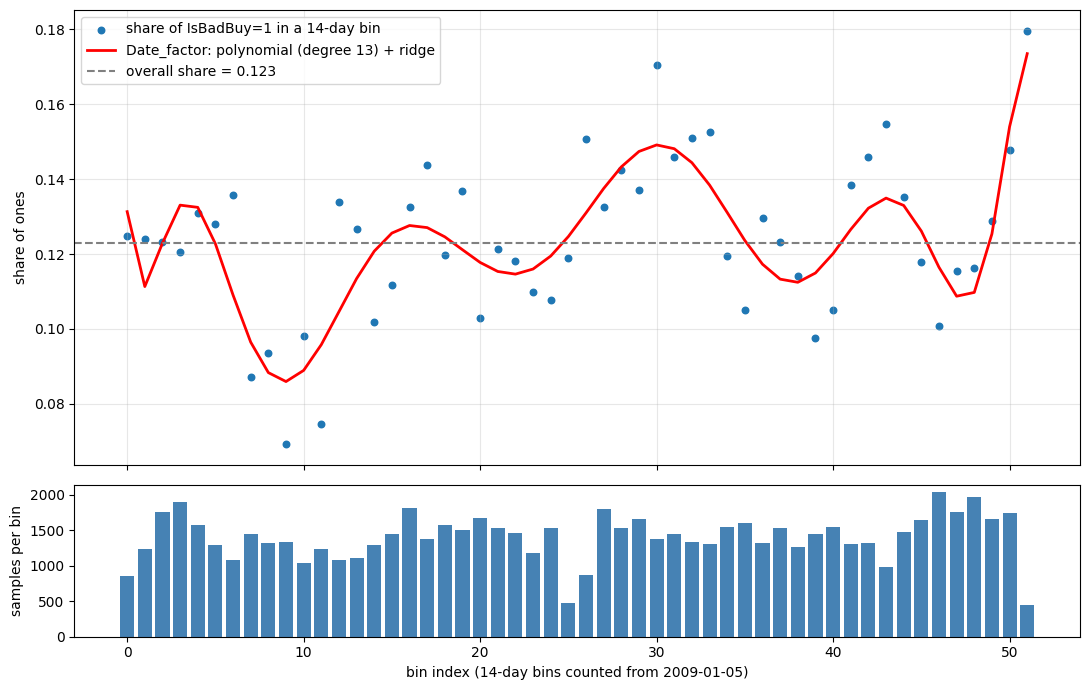

In [10]:
bins = ((X["PurchDate"] - pd.Timestamp("2009-01-05")) // pd.Timedelta(days=DATE_DAYS)).astype(int)
rate, cnt = y.groupby(bins).mean(), bins.value_counts().sort_index()
poly = Pipeline([("ss1", StandardScaler()), ("pt", PolynomialFeatures(13, include_bias=False)),
                 ("ss2", StandardScaler()), ("lr", Ridge(alpha=0.007))]).fit(bins.to_frame("PurchDate"), y)
grid = pd.DataFrame({"PurchDate": np.arange(bins.min(), bins.max() + 1)})

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.scatter(rate.index, rate.values, s=22, label=f"share of IsBadBuy=1 in a {DATE_DAYS}-day bin")
ax.plot(grid["PurchDate"], poly.predict(grid), "r-", lw=2, label="Date_factor: polynomial (degree 13) + ridge")
ax.axhline(y.mean(), ls="--", c="gray", label=f"overall share = {y.mean():.3f}")
ax.set_ylabel("share of ones"); ax.legend(); ax.grid(alpha=0.3)
ax2.bar(cnt.index, cnt.values, color="steelblue"); ax2.set_ylabel("samples per bin")
ax2.set_xlabel(f"bin index ({DATE_DAYS}-day bins counted from 2009-01-05)")
plt.tight_layout(); plt.show()

## 5. `price_factor` and `text_factor`
These are **stacked features**: `price_factor` is a polynomial (degree 3) logistic regression on the cleaned prices, `text_factor` is a logistic regression on the Make/Model/Trim/SubModel tokens. Each plot shows the factor values **sorted** (`i` vs `factor[i]`); the dashed line is the share of ones in the whole dataset. A flat curve at that level would mean the factor carries no information; the wider the range, the more separation. The curves are computed **in-sample**, so the table below also gives the honest out-of-fold AUC.

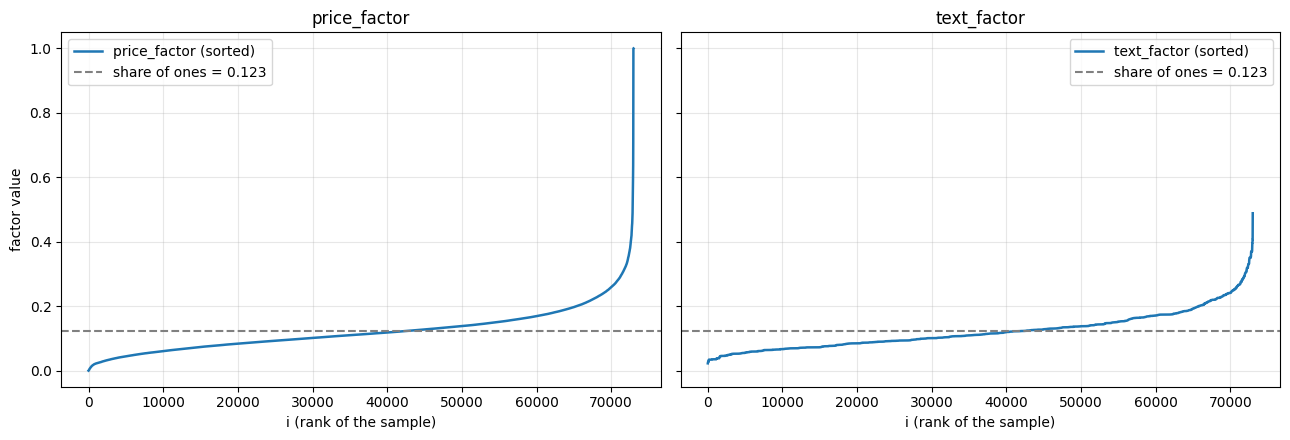

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, c in zip(axes, ["price_factor", "text_factor"]):
    v = np.sort(P[c].to_numpy())
    ax.plot(np.arange(len(v)), v, lw=1.8, label=f"{c} (sorted)")
    ax.axhline(y.mean(), ls="--", c="gray", label=f"share of ones = {y.mean():.3f}")
    ax.set_xlabel("i (rank of the sample)"); ax.set_title(c); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("factor value")
plt.tight_layout(); plt.show()

In [12]:
factors = ["price_factor", "text_factor", "Date_factor"]
oof_f = pd.DataFrame(np.nan, index=X.index, columns=factors)
for tr, va in folds:                                    # factor models are fitted on the training part only
    pp = Preprocessing().fit(X.iloc[tr], y.iloc[tr])
    oof_f.iloc[va] = pp.transform(X.iloc[va])[factors].to_numpy()
pd.DataFrame({"in-sample AUC": {c: roc_auc_score(y, P[c]) for c in factors},
              "out-of-fold AUC": {c: roc_auc_score(y, oof_f[c]) for c in factors}}).round(4)

,in-sample AUC,out-of-fold AUC
price_factor,0.6697,0.6616
text_factor,0.6446,0.6265
Date_factor,0.5399,0.5362


## 6. XGBoost on fold 0 with `Preprocessing` + JDF
Pipeline: `Preprocessing` (fitted on the training part of fold 0) → `JointDistributionFilter` (profiles of train and test) → `XGBClassifier` with the config pasted above. The table lists the importance of every feature (gain, weight, cover) sorted by gain; features that were never used have zeros. Check how high the stacked factors, the relative features and the categoricals rank.

In [13]:
def drop_empty_cats(*frames):
    """Drop categorical columns left without any category after the JDF (all values became NaN)."""
    empty = [c for c in frames[0] if isinstance(frames[0][c].dtype, pd.CategoricalDtype) and len(frames[0][c].cat.categories) == 0]
    return [f.drop(columns=empty) for f in frames]

tr, va = folds[0]
prep = Preprocessing(add_text_binary_matrix=True, **CFG["preprocessing"]).fit(X.iloc[tr], y.iloc[tr])
Xtr, Xva, Xte = (prep.transform(d) for d in (X.iloc[tr], X.iloc[va], X_test))      # before the JDF
jdf = JointDistributionFilter(Xtr, Xte, **CFG["jdf"])
Xtr_j, Xva_j, Xte_j = (jdf.transform(d) for d in (Xtr, Xva, Xte))                  # after the JDF
Xtr_f, Xva_f, Xte_f = drop_empty_cats(Xtr_j, Xva_j, Xte_j)

model = xgb.XGBClassifier(n_estimators=N_ITER, tree_method="hist", enable_categorical=True, eval_metric="auc",
                          random_state=SEED, **CFG["xgb"]).fit(Xtr_f, y.iloc[tr])
print("features:", Xtr_f.shape[1], "| fold 0 valid AUC:", round(roc_auc_score(y.iloc[va], model.predict_proba(Xva_f)[:, 1]), 5))

booster = model.get_booster()
feature_importance = pd.DataFrame({t: pd.Series(booster.get_score(importance_type=t)) for t in ("gain", "weight", "cover")})
feature_importance = feature_importance.reindex(Xtr_f.columns).fillna(0)
feature_importance["gain_share"] = feature_importance["gain"] / feature_importance["gain"].sum()
feature_importance = feature_importance.sort_values("gain", ascending=False)
feature_importance.head(30)

features: 192 | fold 0 valid AUC: 0.79331


,gain,weight,cover,gain_share
WheelType,197.902344,288.0,2337.499268,0.222661
PRIMEUNIT,23.196352,153.0,2808.988525,0.026098
VehicleAge,16.112537,385.0,623.522705,0.018128
Auction,14.590860,440.0,677.061646,0.016416
price_factor,12.177021,1624.0,510.272888,0.013700
REL_DRIFT_AUC_AVG,8.925780,1856.0,406.664795,0.010042
text_factor,8.805319,1473.0,416.467926,0.009907
VehYear,8.217595,700.0,437.441620,0.009246
text__explorer,7.987560,7.0,972.996765,0.008987
REL_DRIFT_RET_AVG,7.505070,1515.0,314.445496,0.008444


## 7. How the JDF works
**Problem.** The test sample is not a perfect copy of the train sample: some categories (zip codes, buyers, models, trims) are frequent in train but rare or absent in test, and some numeric values are typical for one sample only. A tree model happily splits on such values; on the test sample the same branches see almost no data (or levels that were never seen), so the validation score becomes a bad proxy for the leaderboard.

**Idea.** Build a *profile* of every column on the train sample and on the test sample, and replace everything that is not well supported in **both** samples by NaN (a "don't know" that XGBoost routes with a learned default direction):
- **Categorical columns** – the share of a level must be at least `th_cat_train` in train **and** `th_cat_test` in test; other levels become NaN. The surviving category set is the same for all frames (XGBoost requires it).
- **Numeric columns** – *heavy* values (share among non-missing values ≥ `dp`, e.g. zeros, fillers, fixed levels) are treated like categories by their share. The remaining values are judged by a **quantile density**: the sample is cut into `1/dp` equal-mass quantile bins, the density of a bin is `(mass / width) · range` – dimensionless, equal to ≈1 for a uniform distribution, so one threshold fits all columns. A value is kept if the density at its position is at least `th_num_train` (train) **and** `th_num_test` (test); values outside the observed range have density 0.
- **Binary token columns `text__*`** – dropped if the token frequency is below `th_cat_train` in train or `th_cat_test` in test.

**Reading the plots below** (`jdf.distributions` is a generator, one figure per column; the data are shown *after* the filter):
left – train vs test histogram (numeric) or category frequencies (categorical); middle – share of NaN in train/test (the part created by the filter plus the original NaN) and min/max, absolute and relative to `max|x|`; right – box plot (numeric) or the 10 rarest remaining categories.

First, how much does the filter remove?

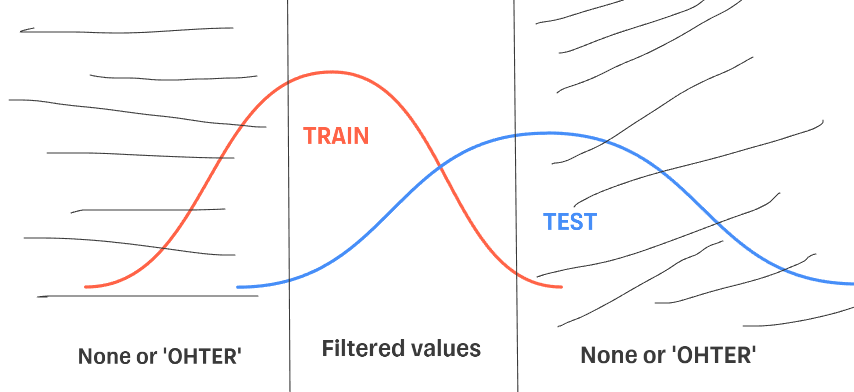

In [14]:
cols = [c for c in jdf.num_cols + jdf.cat_cols if c in Xtr.columns]
masked = pd.DataFrame({"train": [(Xtr_j[c].isna() & Xtr[c].notna()).mean() for c in cols],
                       "test": [(Xte_j[c].isna() & Xte[c].notna()).mean() for c in cols]}, index=cols)
n_text = sum(c.startswith("text__") for c in Xtr.columns)
print(f"text__ columns dropped: {len(jdf.bin_cols_to_drop_)} of {n_text}")
masked.sort_values("test", ascending=False).round(4)       # share of values replaced by NaN

text__ columns dropped: 45 of 209


,train,test
Model,0.5106,0.5167
VNZIP1,0.7732,0.4369
SubModel,0.3615,0.3733
VNST,0.1408,0.0835
Trim,0.0753,0.0760
BYRNO,0.0587,0.0567
Color,0.0134,0.0143
Make,0.0133,0.0131
PRIMEUNIT,0.0009,0.0010
VehYear,0.0000,0.0002


### Distribution plots: scroll through the features manually
Run the first cell once to create the generator, then **re-run the second cell** to get the plot of the next column (it ends with `StopIteration` after the last one). Use `apply_filter=False` to see the data *before* the filter and `columns=[...]` to look at selected columns only.

In [24]:
gen = jdf.distributions(Xtr, Xte , [ "Model", "VNZIP1", "SubModel", "VNST"])          
# Xtr / Xte = output of Preprocessing; plots show the data after the JDF
# gen = jdf.distributions(Xtr, Xte, apply_filter=False)      # the same columns before the filter
# gen = jdf.distributions(Xtr, Xte, columns=[ "Model", "VNZIP1", "Submodel", "VNST"])

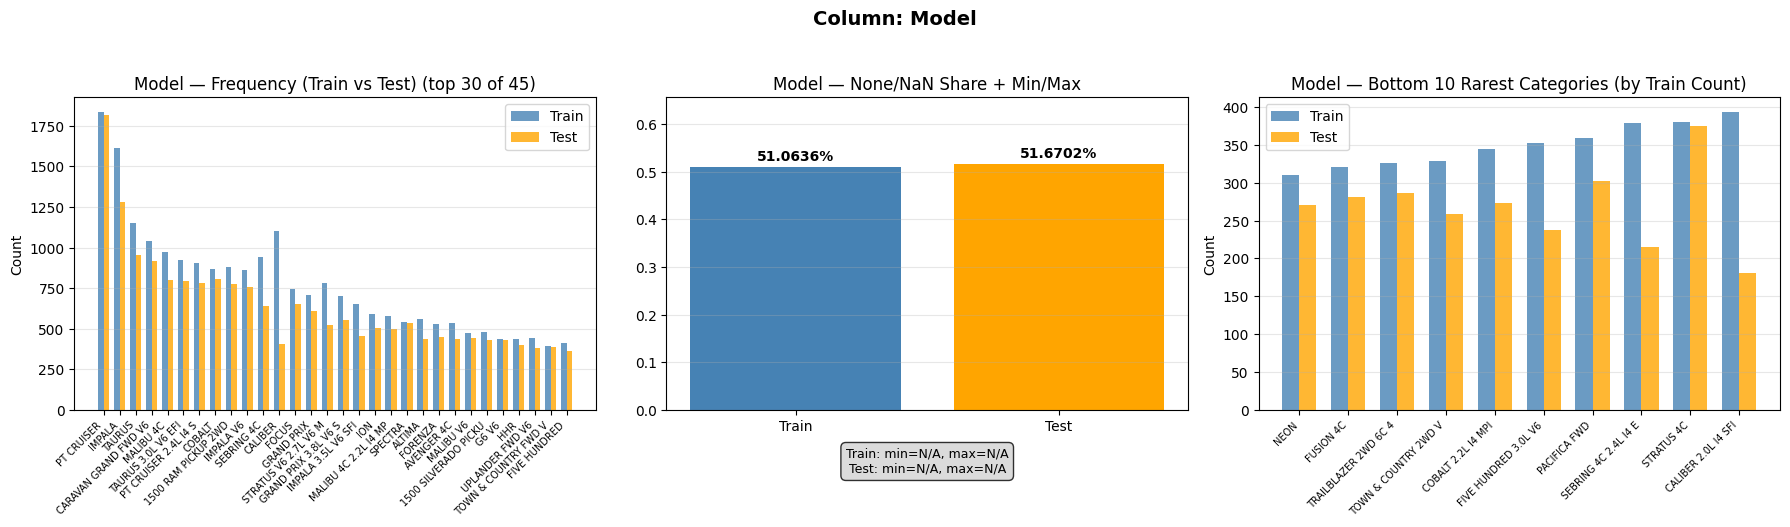

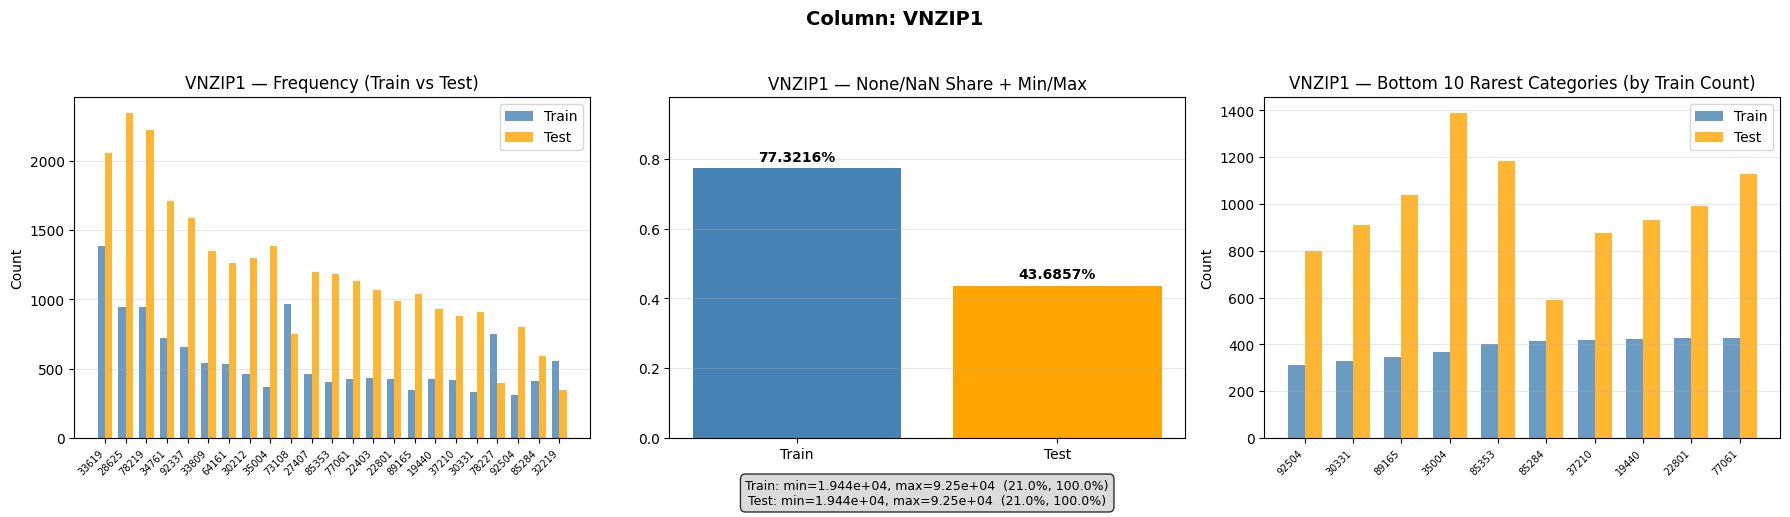

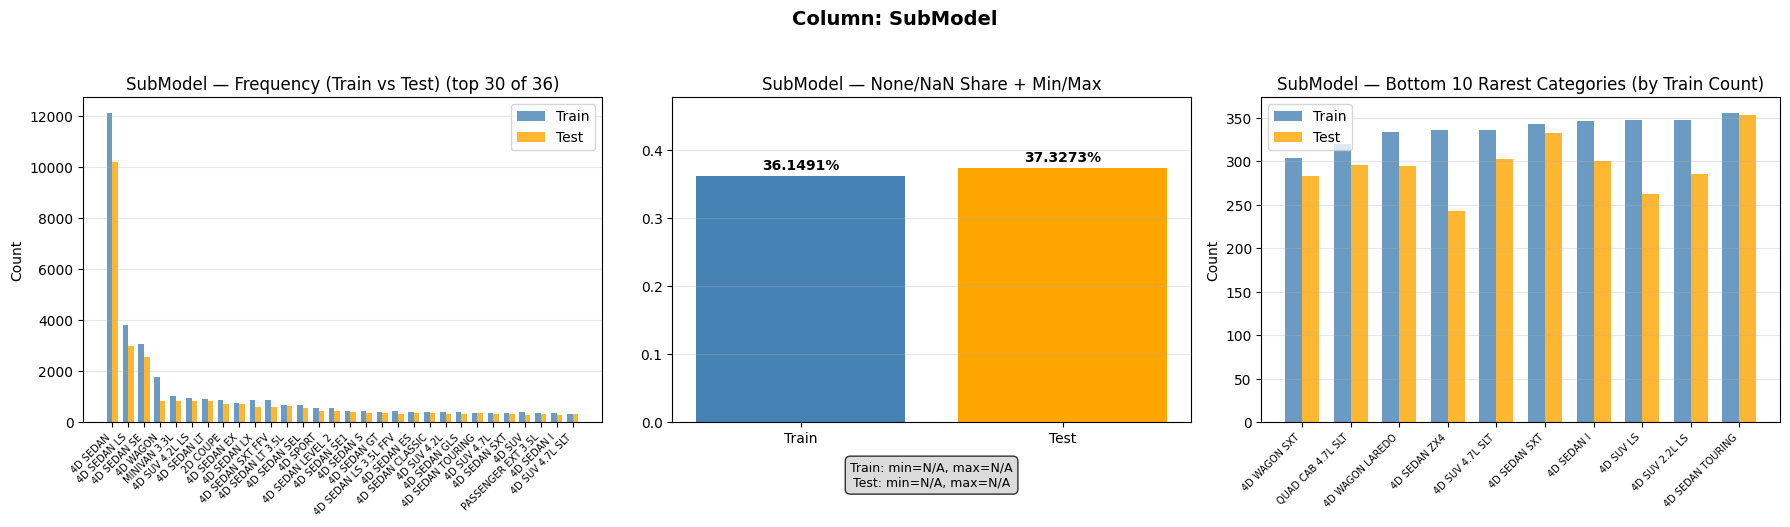

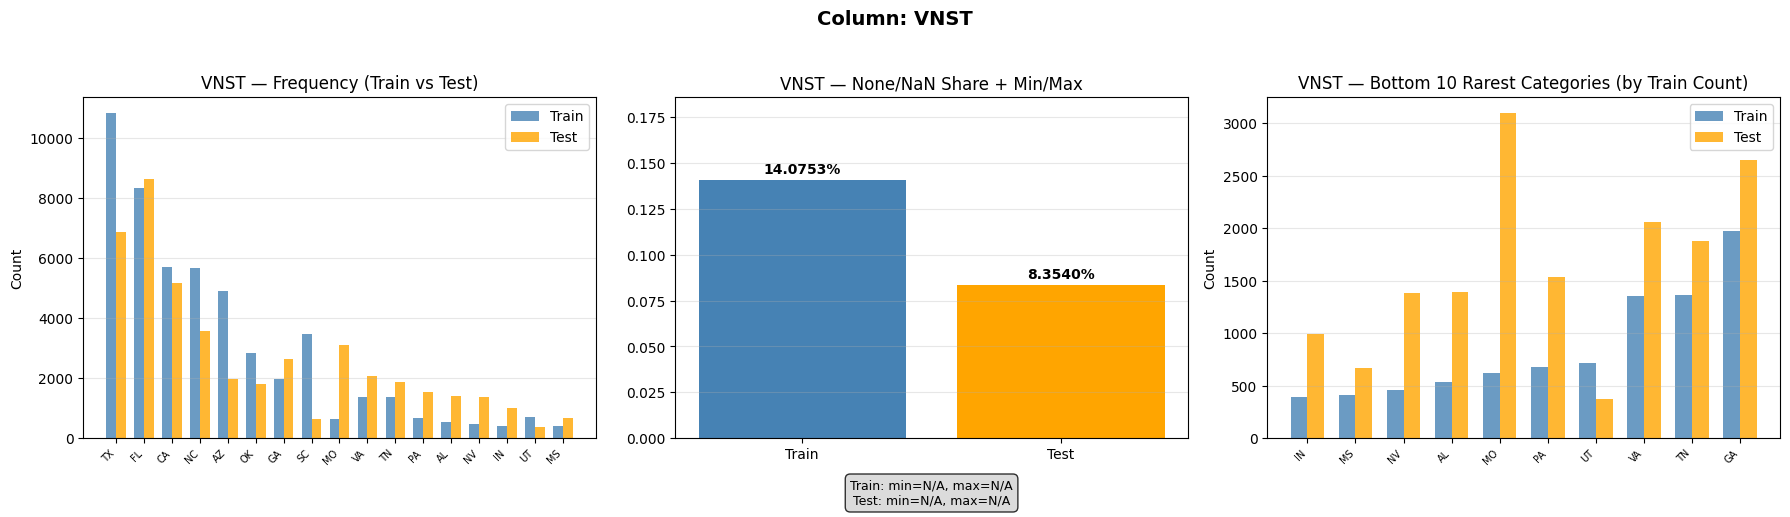

In [25]:
for fig, axes in gen:
    plt.show()            # <- re-run this cell to see the next feature

You can see more details about the JDF effect in the notebook `./compare_solutions/kaggle_xgb_no_jdf.ipynb`